# ДЗ 3 — Гауссовские процессы и временные ряды

В этом ДЗ всего можно получить 40 баллов
* воспроизведение графиков даёт полный балл
* если пример не воспроизведён, мы оцениваем, «сколько изменений нужно внести, чтобы получить полный балл»
* каждое изменение стоит 2 балла

In [1]:
import pymc as pm
import pandas as pd
import numpy as np
import arviz as az
import pytensor.tensor as pt
import matplotlib.pyplot as plt

In [2]:
passengers = pd.read_csv("AirPassengers.csv", parse_dates=["Month"])

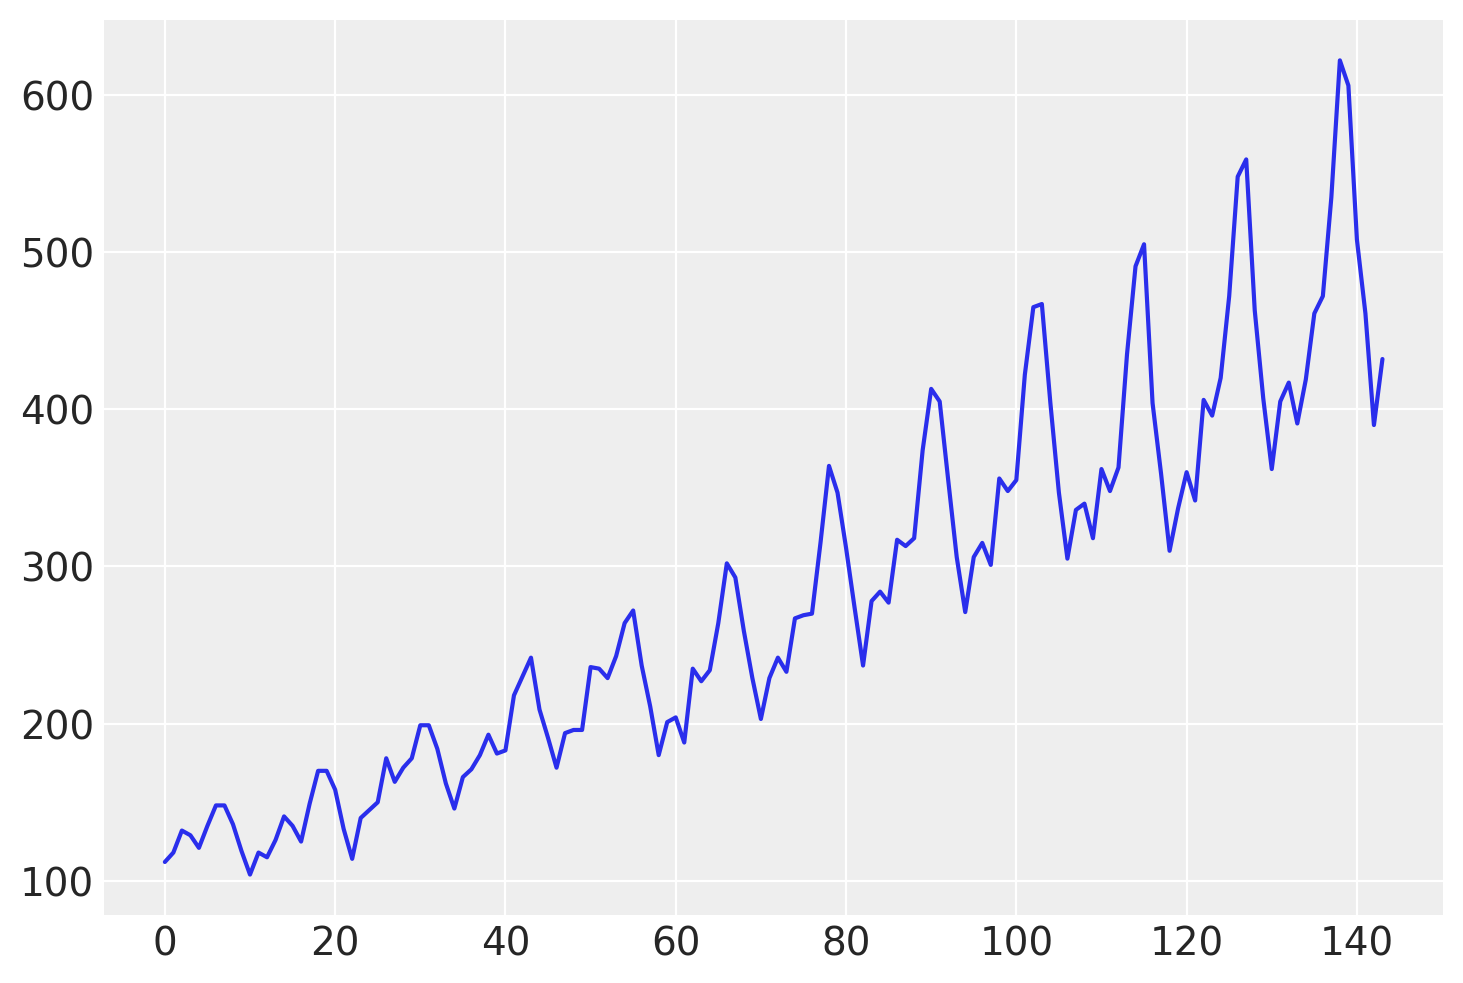

In [3]:
plt.plot(passengers["#Passengers"]);

## Часть 1. Модель с трендом (10 баллов)

В этой части домашнего задания нужно построить маргинальный гауссовский процесс для моделирования числа пассажиров.

1. Обратите внимание, что в данных хорошо выражена сезонность
2. В данных также есть тренд
3. И что немаловажно, число пассажиров — положительное число

### Практические советы

В прикладной статистике распространена практика заменять **часть** анализа априорного предсказательного распределения (prior predictive) вот таким приёмом
```python
# для данных в R^n
time_series: pd.Series
marginal_std = time_series.std()
marginal_mean = time_series.mean()
# для данных в R_+^n (положительные данные)
marginal_log_std = np.log(time_series[time_series>0]).std()
marginal_log_mean = np.log(time_series[time_series>0]).mean()
```
Это не обязательно заменяет всё исследование того, «как выглядит модель», но заметно упрощает работу с байесовскими моделями.

In [4]:
marginal_log_std = np.log(passengers["#Passengers"][passengers["#Passengers"]>0]).std()
marginal_log_mean = np.log(passengers["#Passengers"][passengers["#Passengers"]>0]).mean()

Фиксированные числа слишком конкретны, поэтому нужна некоторая неопределённость, чтобы помочь модели найти оптимальные маргинальные параметры.

> для наших данных в логарифмической шкале стандартное отклонение задаётся в логарифмической шкале — и для среднего, и для std

In [5]:
log_empirical_uncertainty = 0.15

Теперь реализуйте модель

$$
\begin{align}
\text{mlogmean} &\sim \operatorname{Normal}(\text{marginal-log-mean}, \text{log-empirical-uncertainty}) \\
\text{trend} &\sim \operatorname{Normal}(0,?) \\
\text{eps} &\sim \operatorname{LogNormal}(?,?) \\
\text{obs} &\sim \operatorname{LogNormal}(f(\text{mlogmean},\text{trend}),\text{eps})\\
\end{align}
$$

In [6]:
with pm.Model(coords=dict(time=passengers["Month"])) as model1:
    # центрируем данные, чтобы E[X] = 0: это распространённый приём, упрощающий рассуждения
    months = pm.ConstantData("month", np.arange(len(passengers)) - len(passengers)//2, dims="time")
    m_log_mean = ...
    log_trend = ...
    log_mean = ... # вычислите из months, log_trend, m_log_mean
    eps = ...
    obs = pm.LogNormal("obs", log_mean, eps, observed=passengers["#Passengers"], dims="time")

In [7]:
with model1:
    prior = pm.sample_prior_predictive()

Sampling: [eps, m_log_mean, obs, trend]


Убедитесь, что число пассажиров не принимает огромных значений.

In [ ]:
az.plot_ppc(prior, group="prior");

In [9]:
with model1:
    trace = pm.sample()
    trace.extend(pm.sample_posterior_predictive(trace))

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [m_log_mean, trend, eps]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.
Sampling: [obs]


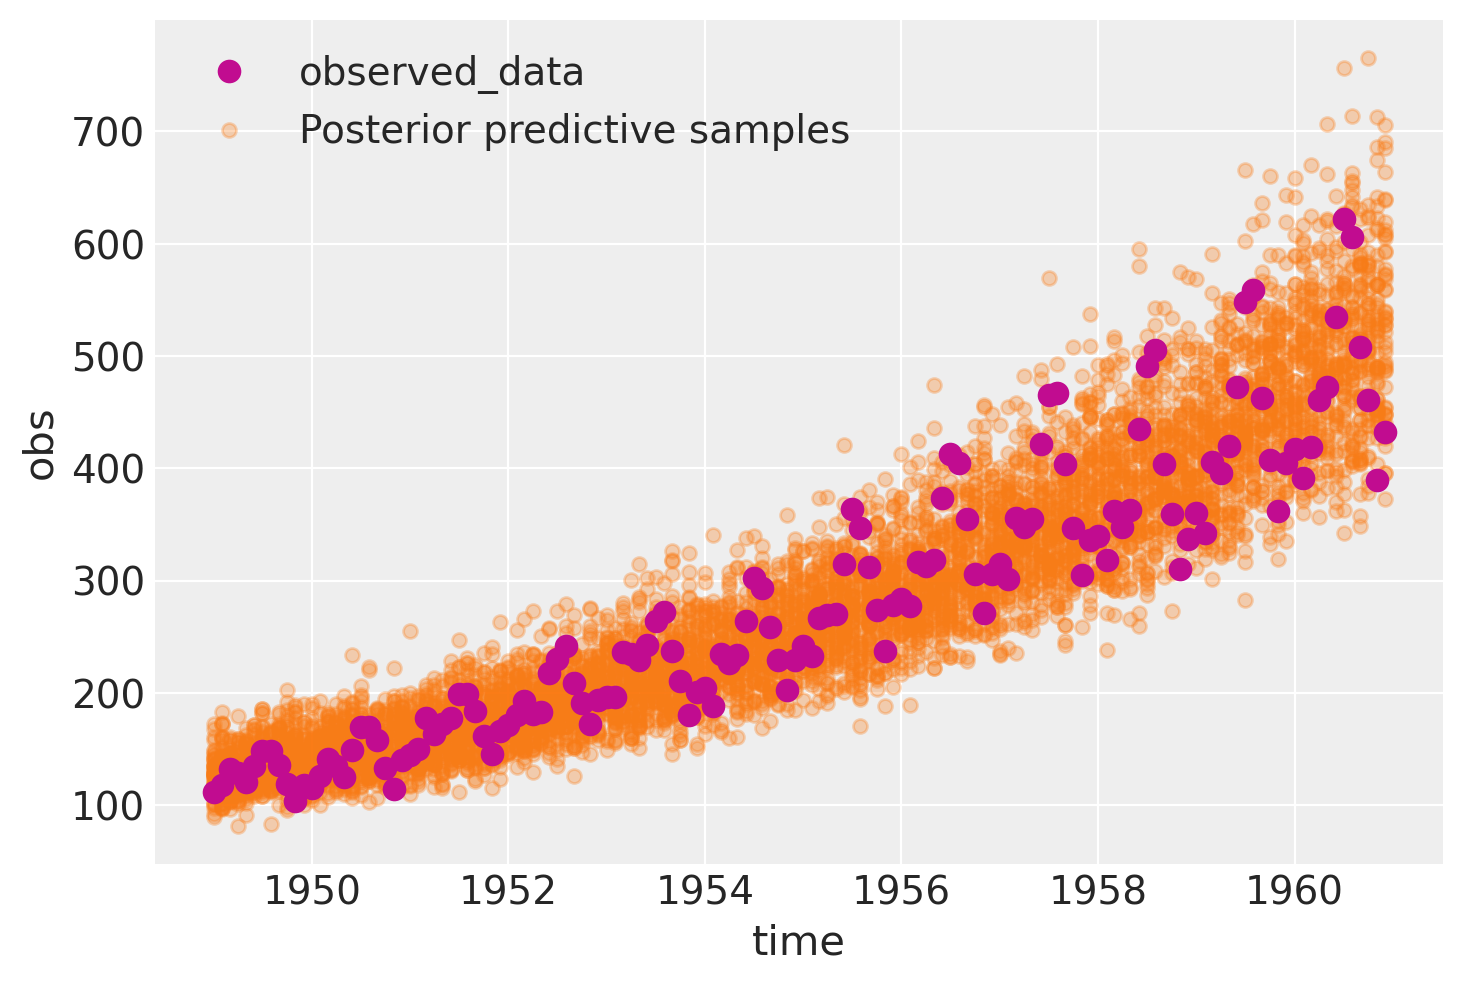

In [10]:
az.plot_lm("obs", trace);

## Часть 2. Простой гауссовский процесс (10 баллов)

Скопируйте свою модель в следующую ячейку и назовите её model2 — мы заменим модель на модель с гауссовским процессом

$$
\begin{align}
\text{mlogmean} &\sim \operatorname{Normal}(?,?) \\
\text{trend} &\sim \operatorname{Normal}(0,?) \\
\text{eps} &\sim \operatorname{LogNormal}(?,?) \\
\alpha_s &\sim \operatorname{LogNormal}(?, ?)\\
l_s &\sim \operatorname{Gamma}(?, ?)\\
K &= \alpha_s\operatorname{Periodic}(\text{period}=12, l_s)\\
\text{seasonal} &\sim \mathcal{GP}(\text{time}, 0, K)\\
\text{obs} &\sim \operatorname{LogNormal}(f(\text{mlogmean},\text{trend}, \text{seasonal}),\text{eps})\\
\end{align}
$$
где для $\operatorname{Periodic}(\text{period}=12, \dots)$ нужно задать **масштаб длины** (lengthscale) и **амплитуду** (magnitude)

Можно почитать:
* https://www.pymc.io/projects/examples/en/latest/gaussian_processes/GP-Latent.html
* https://www.pymc.io/projects/examples/en/latest/gaussian_processes/GP-MeansAndCovs.html

In [11]:
with pm.Model(coords=dict(time=passengers["Month"])) as model2:
    # центрируем данные, чтобы E[X] = 0: это распространённый приём, упрощающий рассуждения
    months = pm.ConstantData("month", np.arange(len(passengers)) - len(passengers)//2, dims="time")

    # скопируйте из предыдущей модели
    m_log_mean = ...
    log_trend = ...
    log_mean = ... # вычислите из months, log_trend, m_log_mean
    eps = ...

    # пора реализовать гауссовский процесс
    # сначала априорные распределения
    alpha_s = ...
    # у нас помесячные данные — учтите это
    ls = ...
    periodic = ...
    assert isinstance(periodic, pm.gp.cov.Periodic)
    
    gp = pm.gp.Latent(cov_func=periodic * alpha_s)
    seasonality = gp.prior("seasonality", months[:, None])

    pm.Normal("log_obs", log_mean + seasonality, eps, observed=np.log(passengers["#Passengers"]), dims="time")

In [ ]:
pm.model_to_graphviz(model2)

Чтобы быстро оценить гауссовский процесс, найдём MAP-оценку (find MAP)

In [29]:
with model2:
    map = pm.find_MAP()
    ppc = pm.sample_posterior_predictive([map]*100)

Sampling: [log_obs]


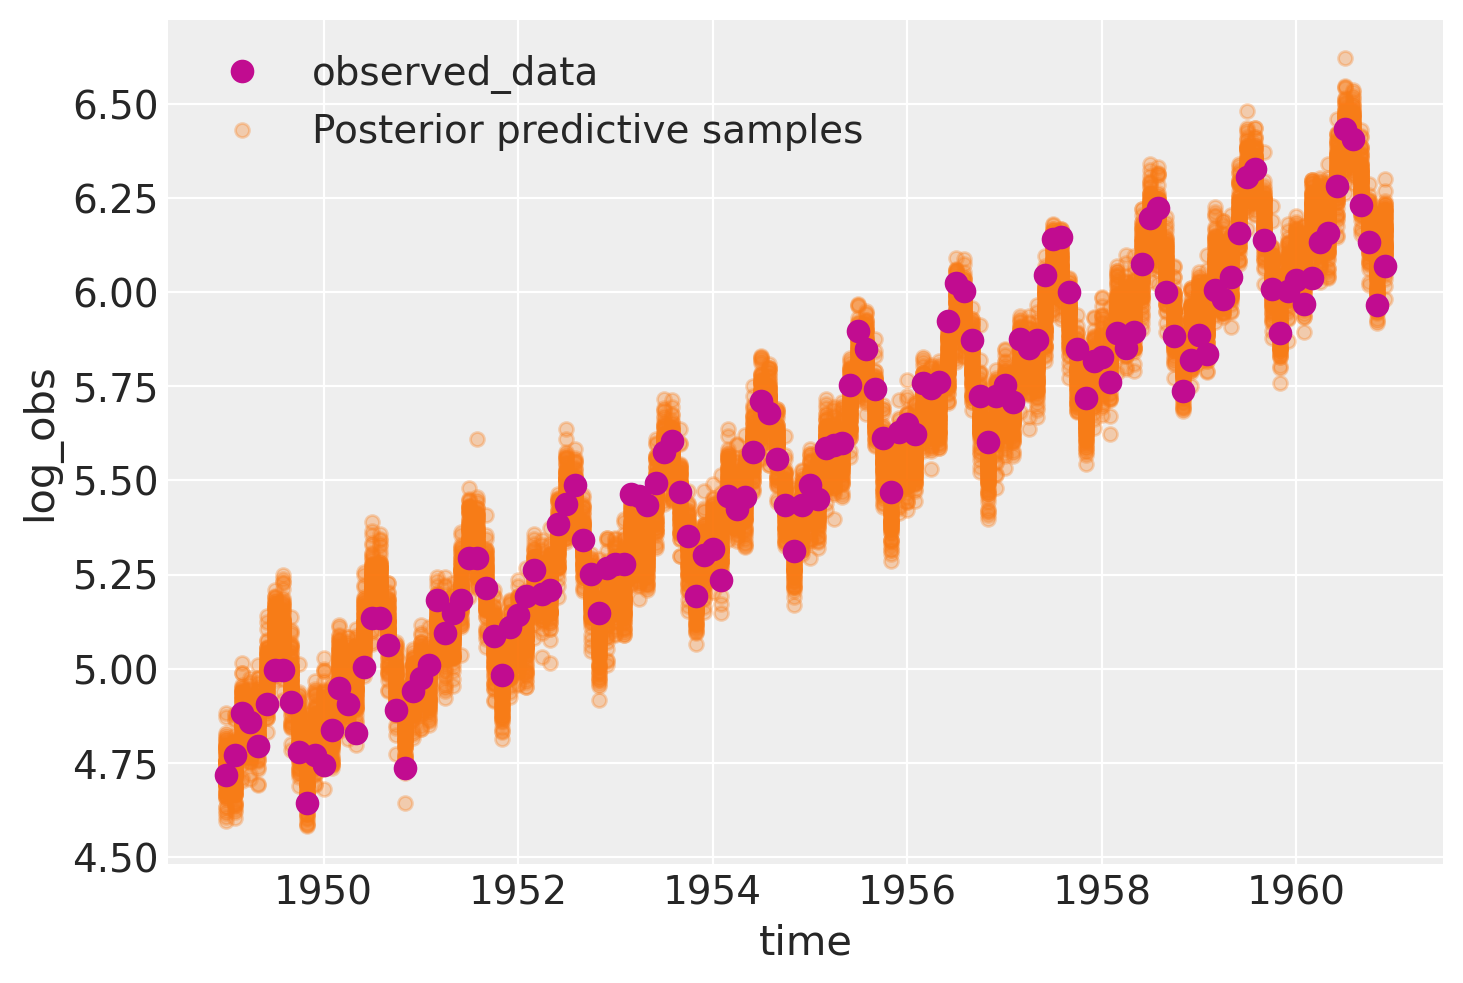

In [30]:
az.plot_lm("log_obs", ppc, num_samples=100);

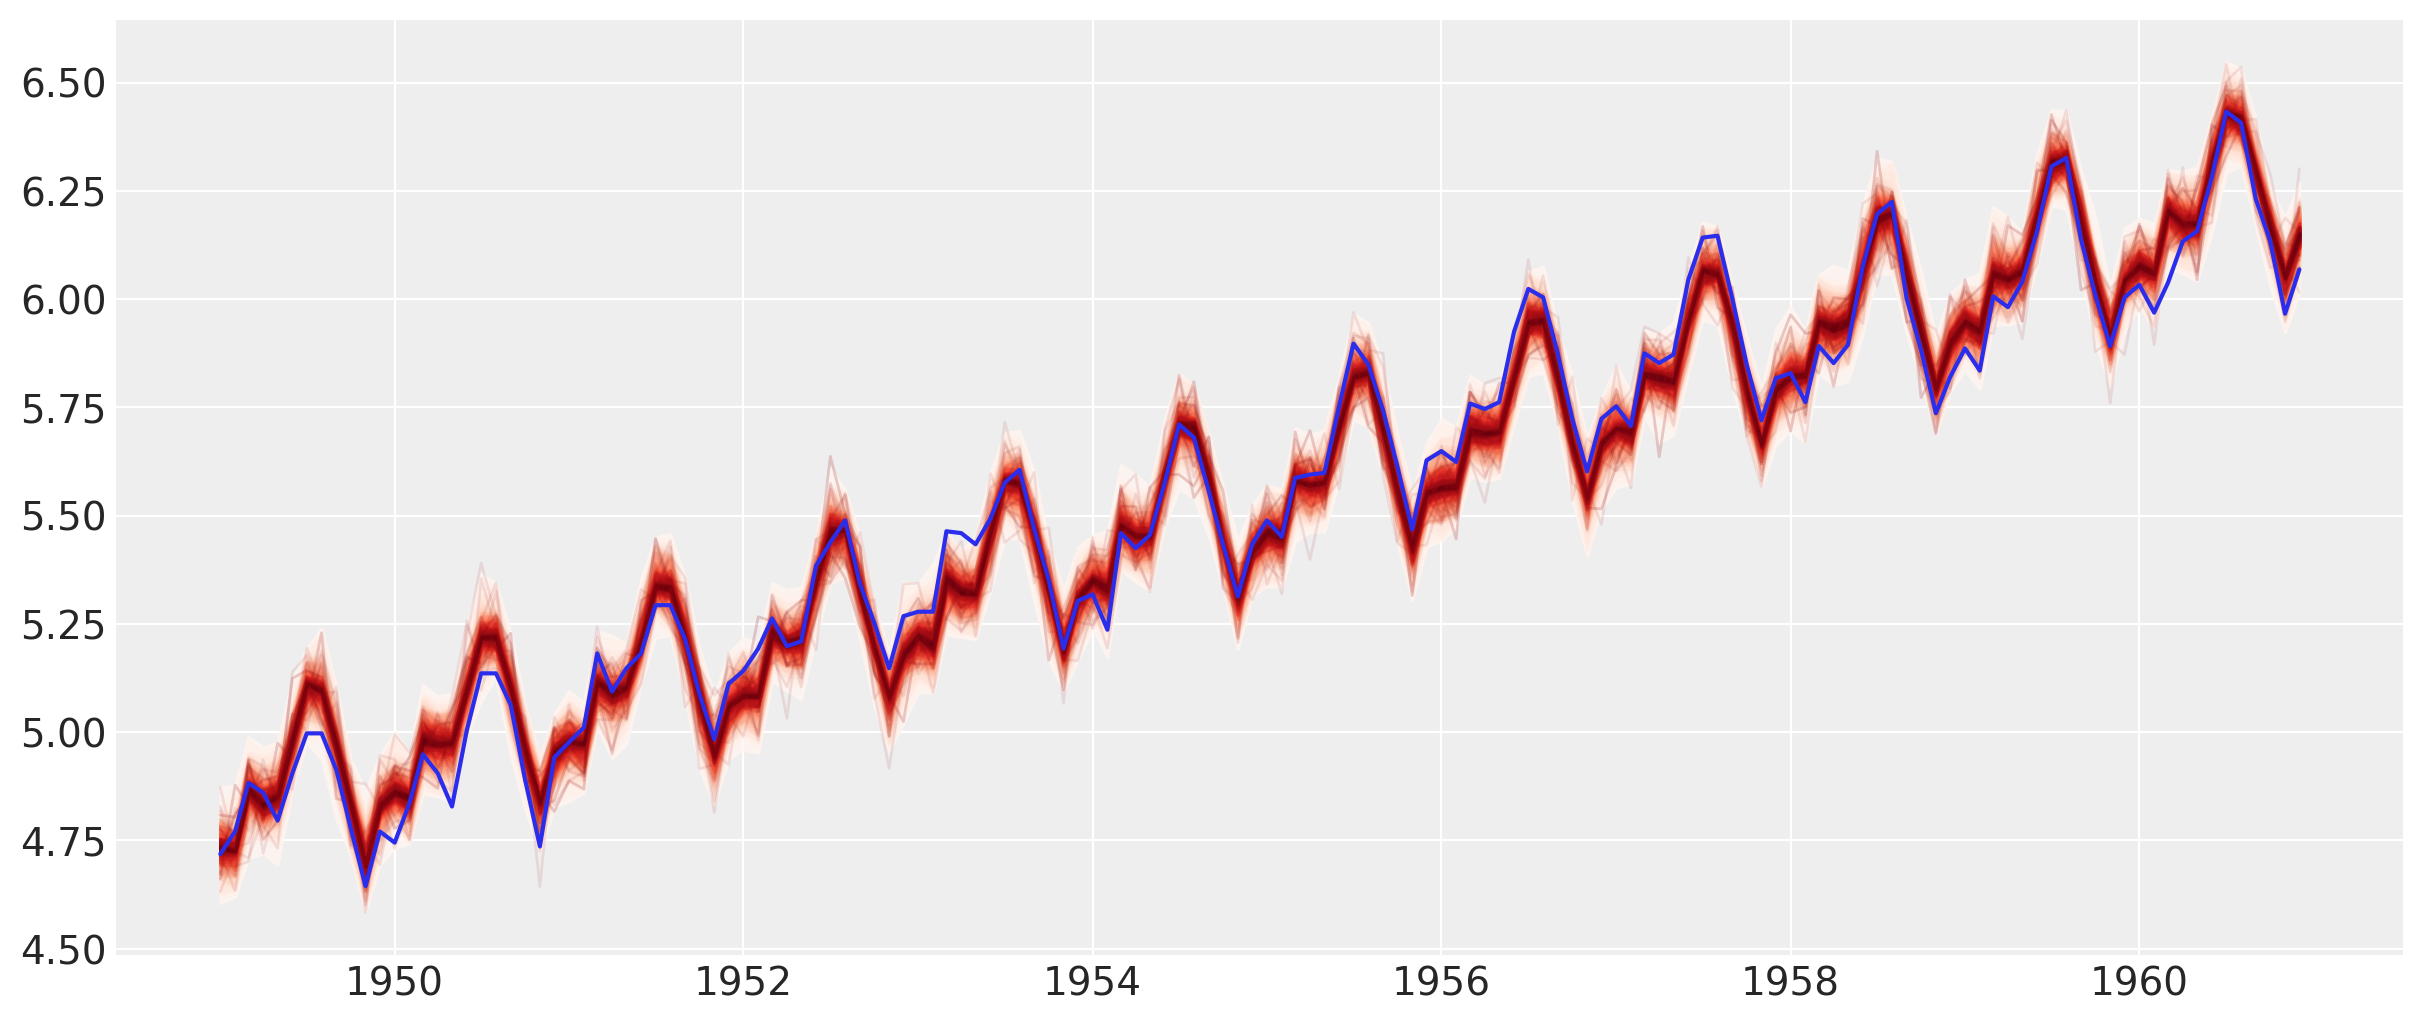

In [31]:
from pymc.gp.util import plot_gp_dist
fig = plt.figure(figsize=(12, 5))
ax = fig.gca()


plot_gp_dist(ax, az.extract(ppc.posterior_predictive)["log_obs"].T, ppc.posterior_predictive.time.values)
ax.plot(ppc.posterior_predictive.time.values, np.log(passengers["#Passengers"]));

Можно попробовать запустить обычное сэмплирование, но оно будет не таким быстрым, и появятся дивергенции.

> Это необязательно, можно сделать из любопытства

In [16]:
with model2:
    trace2 = pm.sample()

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [m_log_mean, trend, alpha_s, ls_s, eps, seasonality_rotated_]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 367 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
There were 251 divergences after tuning. Increase `target_accept` or reparameterize.


In [17]:
with model2:
    ppc_large = pm.sample_posterior_predictive(trace2)

Sampling: [log_obs]


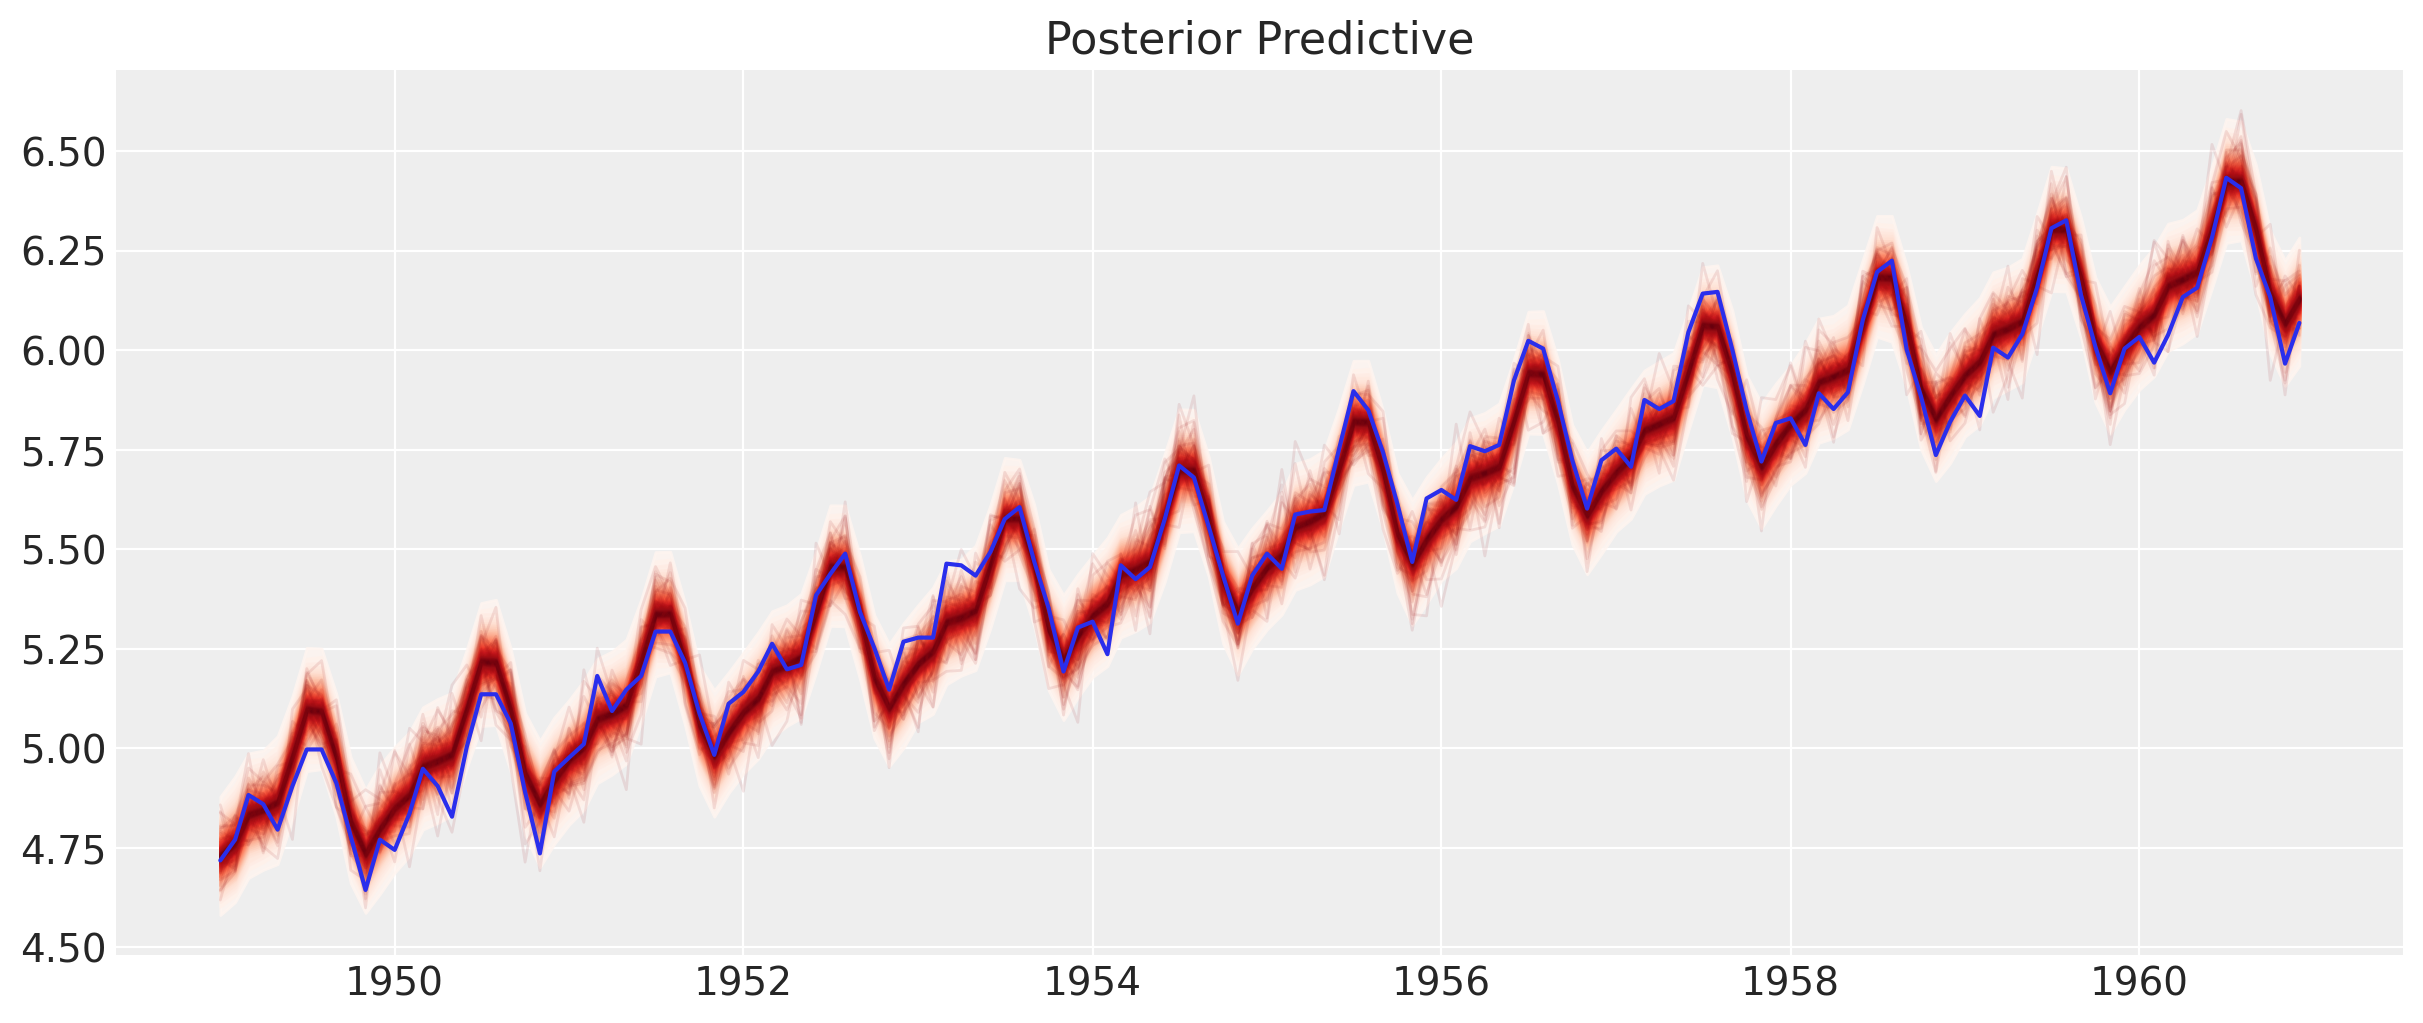

In [18]:
fig = plt.figure(figsize=(12, 5))
ax = fig.gca()


plot_gp_dist(ax, az.extract(ppc_large.posterior_predictive)["log_obs"].T, ppc_large.posterior_predictive.time.values)
ax.plot(ppc_large.posterior_predictive.time.values, np.log(passengers["#Passengers"]))
plt.title("Posterior Predictive");

## Часть 3. Признаки Фурье (10 баллов)

Построенный нами гауссовский процесс медленно сэмплируется. Из-за этого на практике такие гауссовские процессы используют редко.

Существуют практические подходы к моделированию сезонных временных рядов. Один из самых популярных — признаки Фурье (Fourier features).

* https://arxiv.org/abs/2006.10739
* Prophet использует признаки Фурье https://github.com/facebook/prophet/blob/c00f6a2d72229faa6acee8292bc01e14f16f599c/python/prophet/forecaster.py#L455
* Их не стоит недооценивать

Чтобы применить их на практике, вот фрагмент кода, который строит такие признаки для заданной периодичности.

In [32]:
from collections import namedtuple
from enum import Enum

Season = namedtuple("Season", "period,order")

class Daily(Season, Enum):
    Week = 7.0, 3
    Year = 365.25, 5
    Month = 365.25 / 12, 10

class Monthly(Season, Enum):
    Year = 12, 5
    Month = 1, 10

In [33]:
Daily.Year

<Daily.Year: Season(period=365.25, order=5)>

In [34]:
def fourier_series(
    time: pt.TensorLike, 
    *, 
    season: Season,
) -> pt.TensorVariable:
    """Строит ряд Фурье.

    Параметры
    ---------
    time : pt.TensorLike
        Временная ось
    season: Season
        Содержит период и порядок аппроксимации

    Возвращает
    ----------
    pt.TensorVariable
        Базисные функции Фурье, отмасштабированные до единичной дисперсии по временной оси
    """
    if (season.order * 2) > season.period:
        raise ValueError("(season.order * 2) > season.period length causes correlated feature")
    time = pt.as_tensor(time)
    orders = pt.arange(1, season.order + 1)
    return 2**0.5 * pt.stack(
        [
            pt.sin(2 * pt.pi * time[:, None] * orders / season.period),
            pt.cos(2 * pt.pi * time[:, None] * orders / season.period),
        ],
        axis=-1,
    ).reshape((-1, season.order * 2))

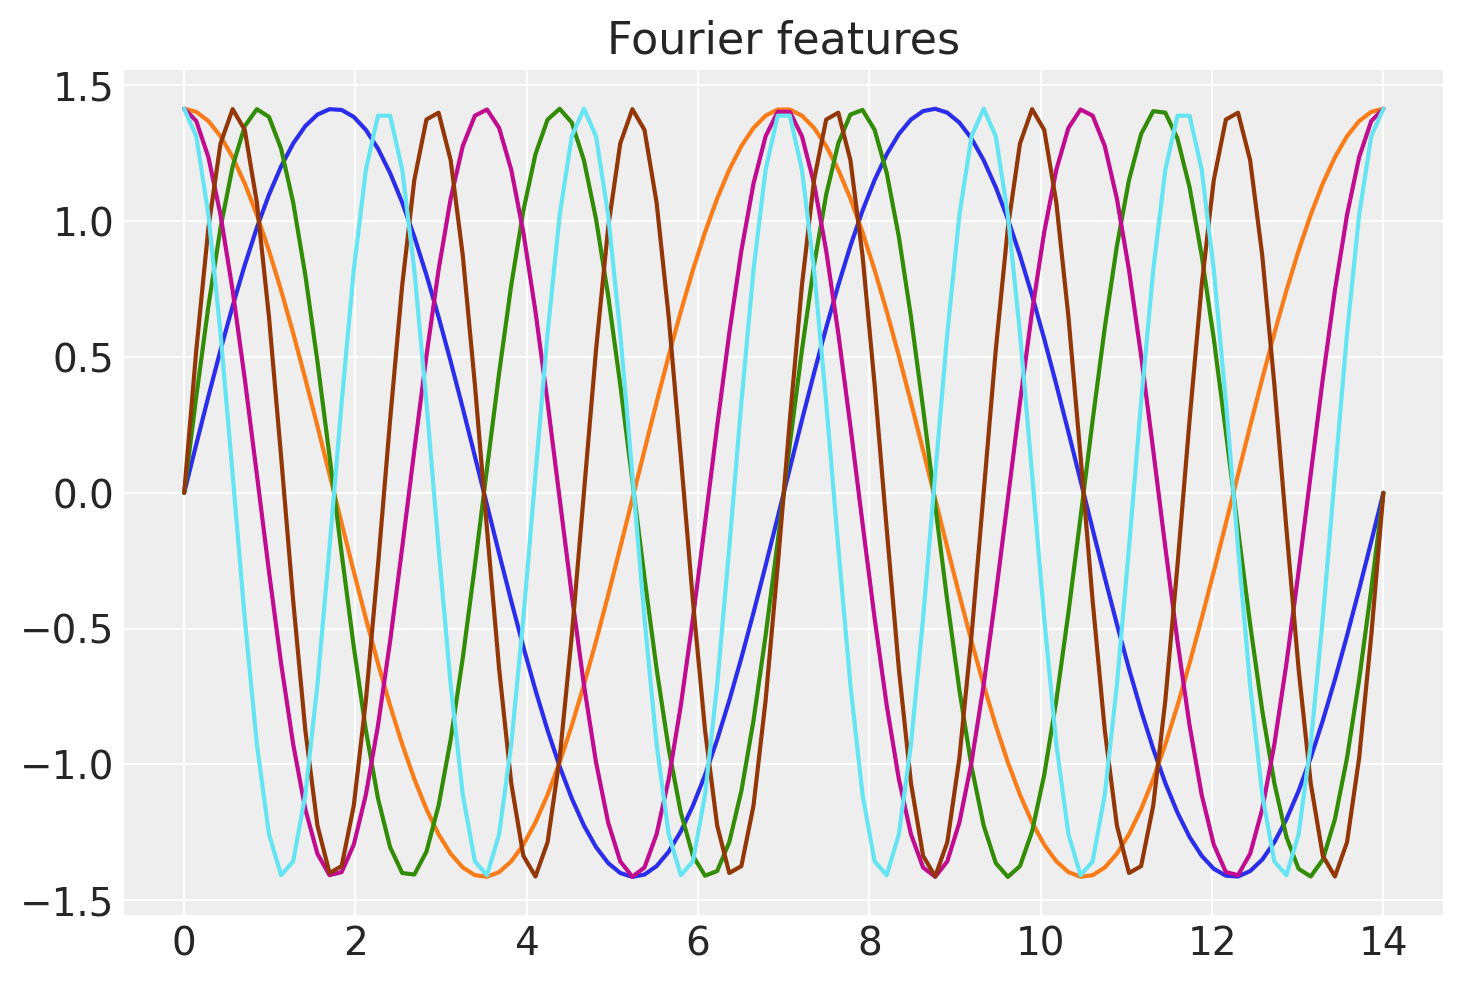

In [35]:
x = np.linspace(0, 14, 100)
plt.plot(x, fourier_series(x, season=Daily.Week).eval())
plt.title("Fourier features");

Теперь замените сезонный латентный гауссовский процесс на годовую сезонность в виде регрессии.

```python
alpha = pm.Normal("alpha", 0, sigma, shape=season.order * 2)
features = fourier_series(months, season=season)
seasonality = features @ alpha
```

In [36]:
with pm.Model(coords=dict(time=passengers["Month"])) as model3:
    # скопируйте из предыдущей модели
    m_log_mean = ...
    log_trend = ...
    log_mean = ... # вычислите из months, log_trend, m_log_mean
    eps = ...

    # пора реализовать периодическую часть на признаках Фурье
    # сначала априорные распределения
    # используйте фрагмент кода выше
    alpha = ...
    seasonality = ...

    pm.Normal("log_obs", log_mean + seasonality, eps, observed=np.log(passengers["#Passengers"]), dims="time")

In [37]:
with model3:
    trace3 = pm.sample()
    trace3.extend(pm.sample_posterior_predictive(trace3))

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [m_log_mean, trend, alpha_s, eps]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Sampling: [log_obs]


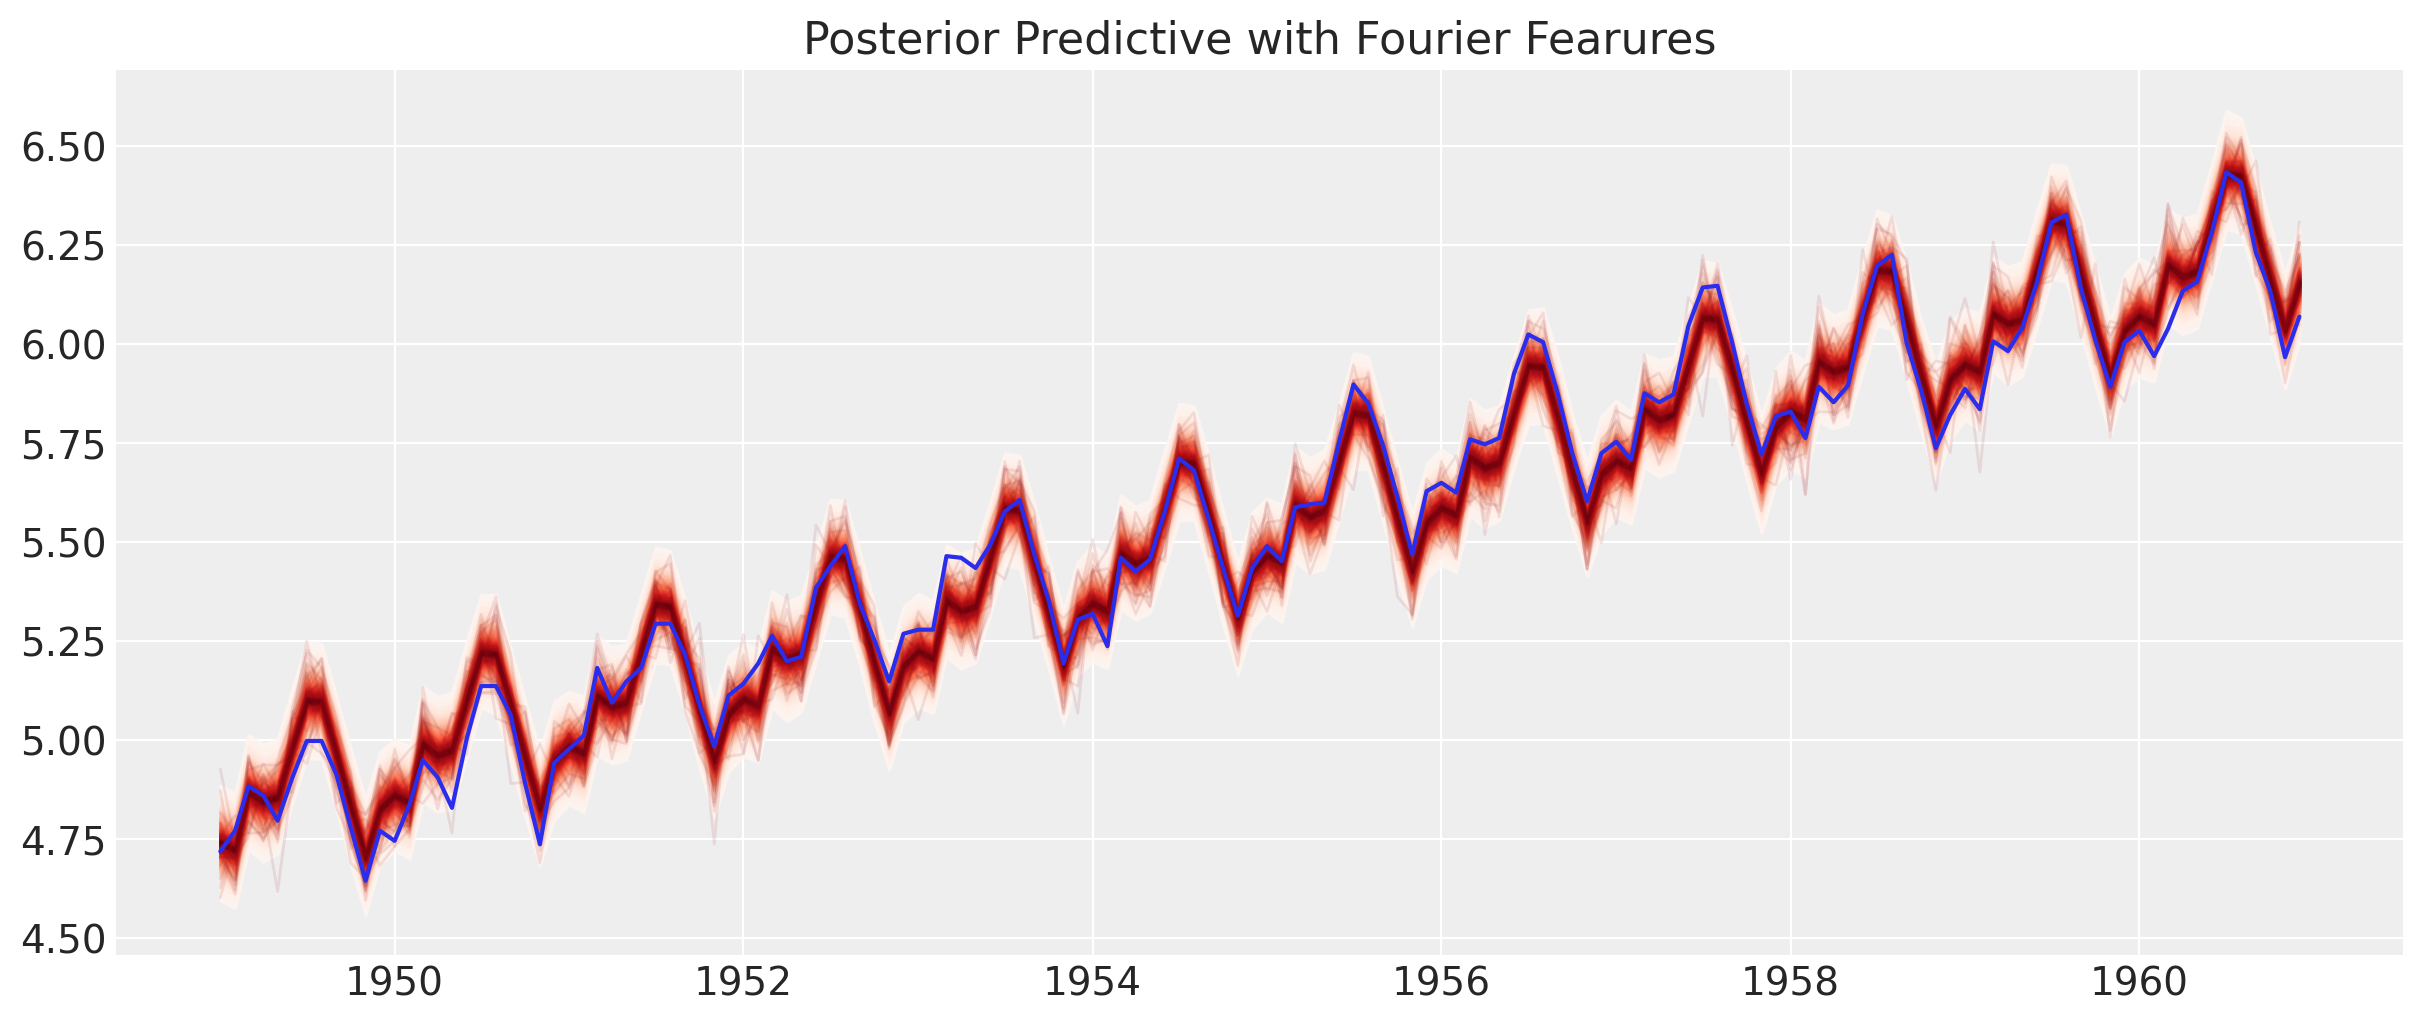

In [72]:
fig = plt.figure(figsize=(12, 5))
ax = fig.gca()


plot_gp_dist(ax, az.extract(trace3.posterior_predictive)["log_obs"].T, trace3.posterior_predictive.time.values)
ax.plot(trace3.posterior_predictive.time.values, np.log(passengers["#Passengers"]))
plt.title("Posterior Predictive with Fourier Fearures");

## Часть 4. HSGP (10 баллов)
В большинстве случаев одних лишь тренда и сезонности недостаточно. Структурные изменения могут приводить к коррелированным во времени ошибкам (остаткам), которые не подчиняются никакому сезонному паттерну.

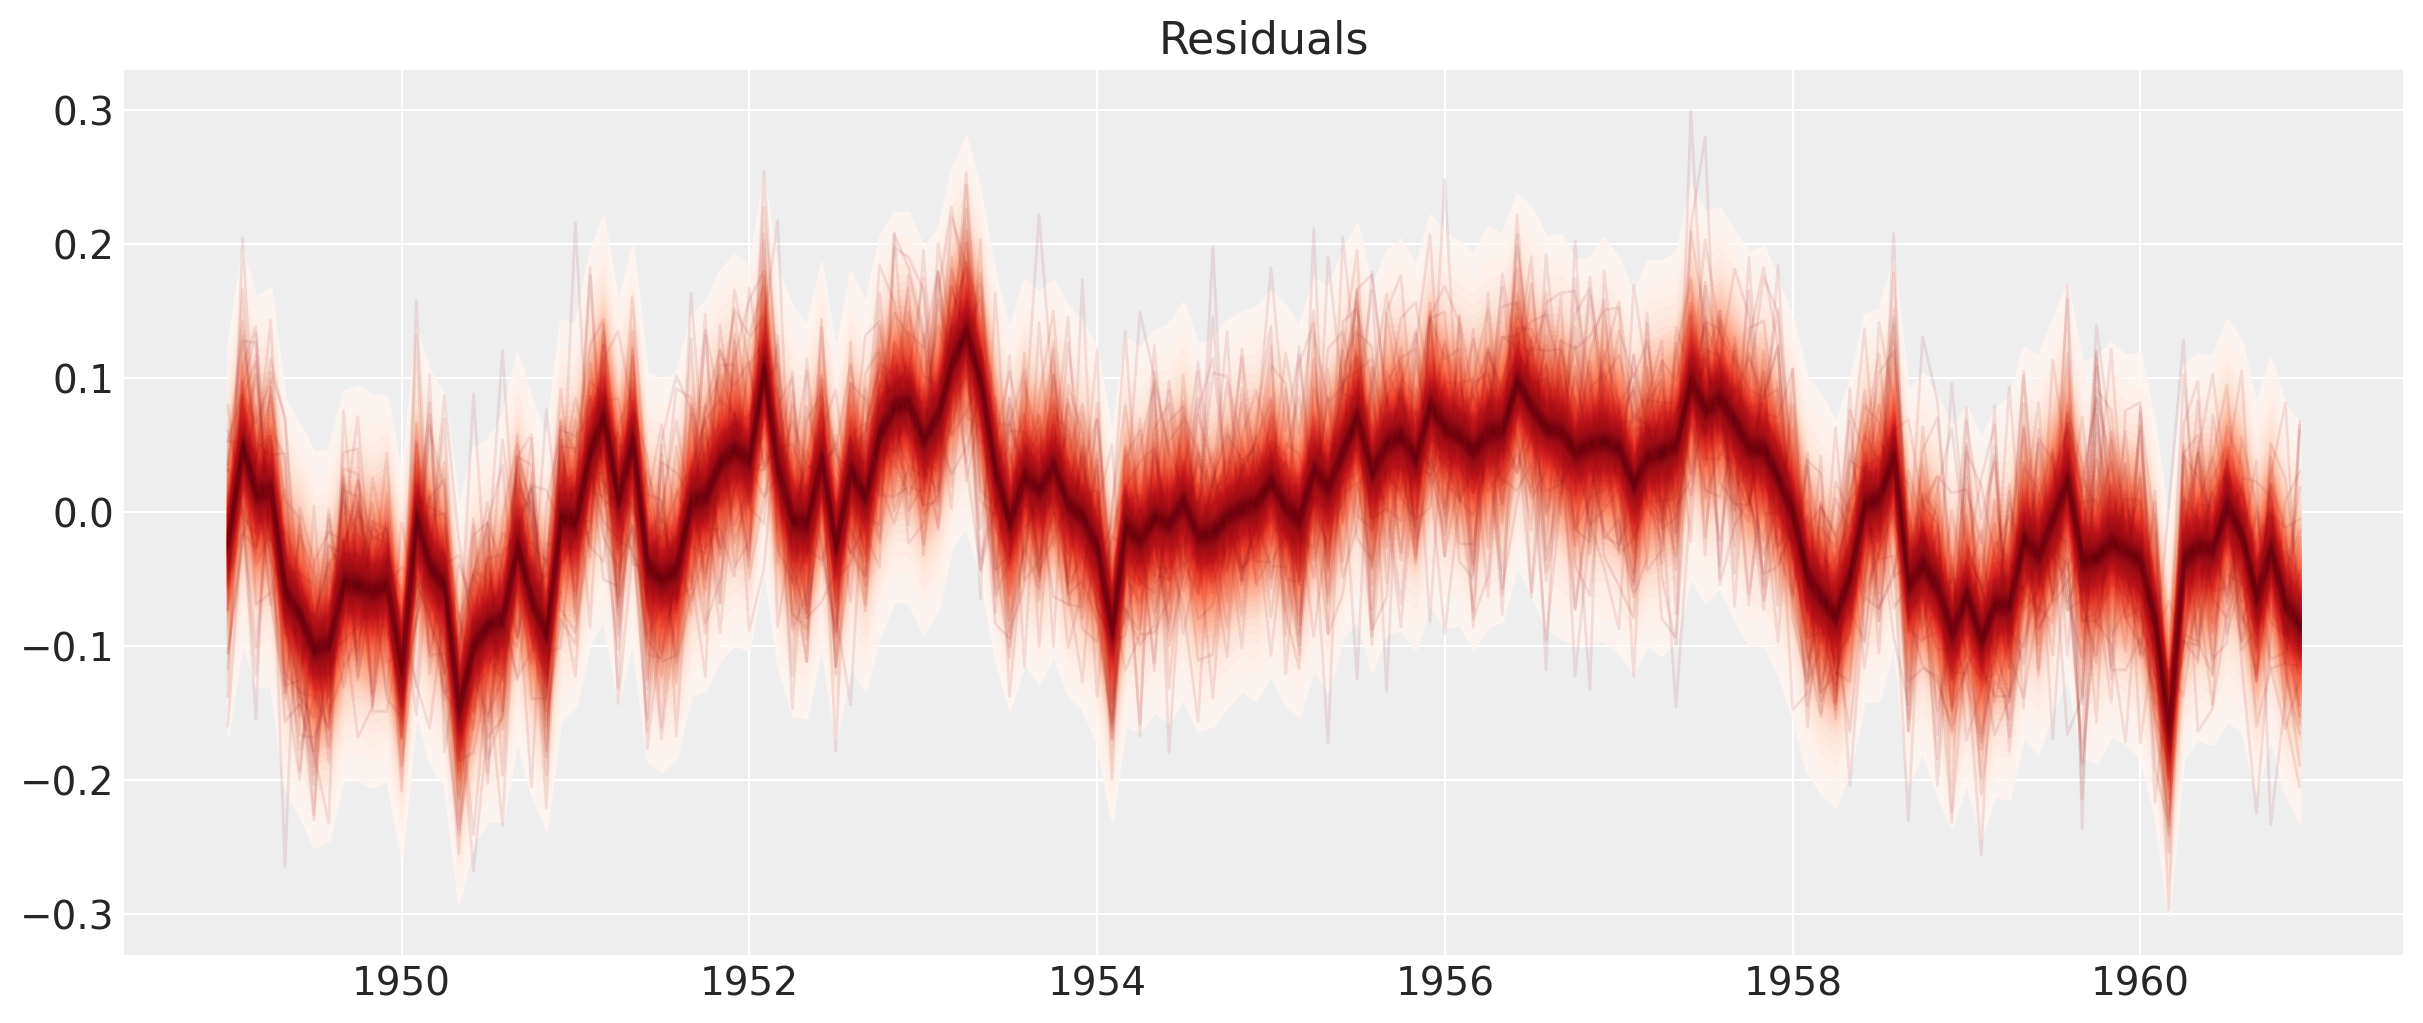

In [40]:
fig = plt.figure(figsize=(12, 5))
ax = fig.gca()

residuals = np.log(passengers["#Passengers"].values) - az.extract(trace3.posterior_predictive)["log_obs"].values.T
plot_gp_dist(ax, residuals, trace3.posterior_predictive.time.values)
plt.title("Residuals");

Существует аппроксимация гауссовского процесса под названием HSGP (Hilbert Space GP)

* https://arxiv.org/abs/2004.11408
* https://www.pymc.io/projects/docs/en/stable/api/gp/generated/pymc.gp.HSGP.html
* https://discourse.pymc.io/t/pymcon-web-series-03a-introduction-to-hilbert-space-gps-hsgps-in-pymc-mar-15-2023-bill-engels/11533

Примеров пока немного — метод совсем свежий. Чтобы было ещё интереснее, создадим более детальный временной ряд — можно считать, что это дневные данные.

### Под капотом

HSGP — это аппроксимация в частотной области; можно даже посмотреть, как выглядят собственные функции

In [49]:
L = [6] # [-L, L] — область аппроксимации
m = [7] # число базисных векторов
X = np.linspace(-5, 5) # область входных данных
# собственные значения лапласиана
eig_vals = pm.gp.hsgp_approx.calc_eigenvalues(L, m)
# собственные функции лапласиана
eig_vecs = pm.gp.hsgp_approx.calc_eigenvectors(X[:, None], L, eig_vals, m)

In [63]:
eig_vecs.shape

(50, 7)

In [64]:
eig_vals

array([[ 0.27415568,  0.27415568],
       [ 1.09662271,  1.09662271],
       [ 2.4674011 ,  2.4674011 ],
       [ 4.38649084,  4.38649084],
       [ 6.85389195,  6.85389195],
       [ 9.8696044 ,  9.8696044 ],
       [13.43362821, 13.43362821]])

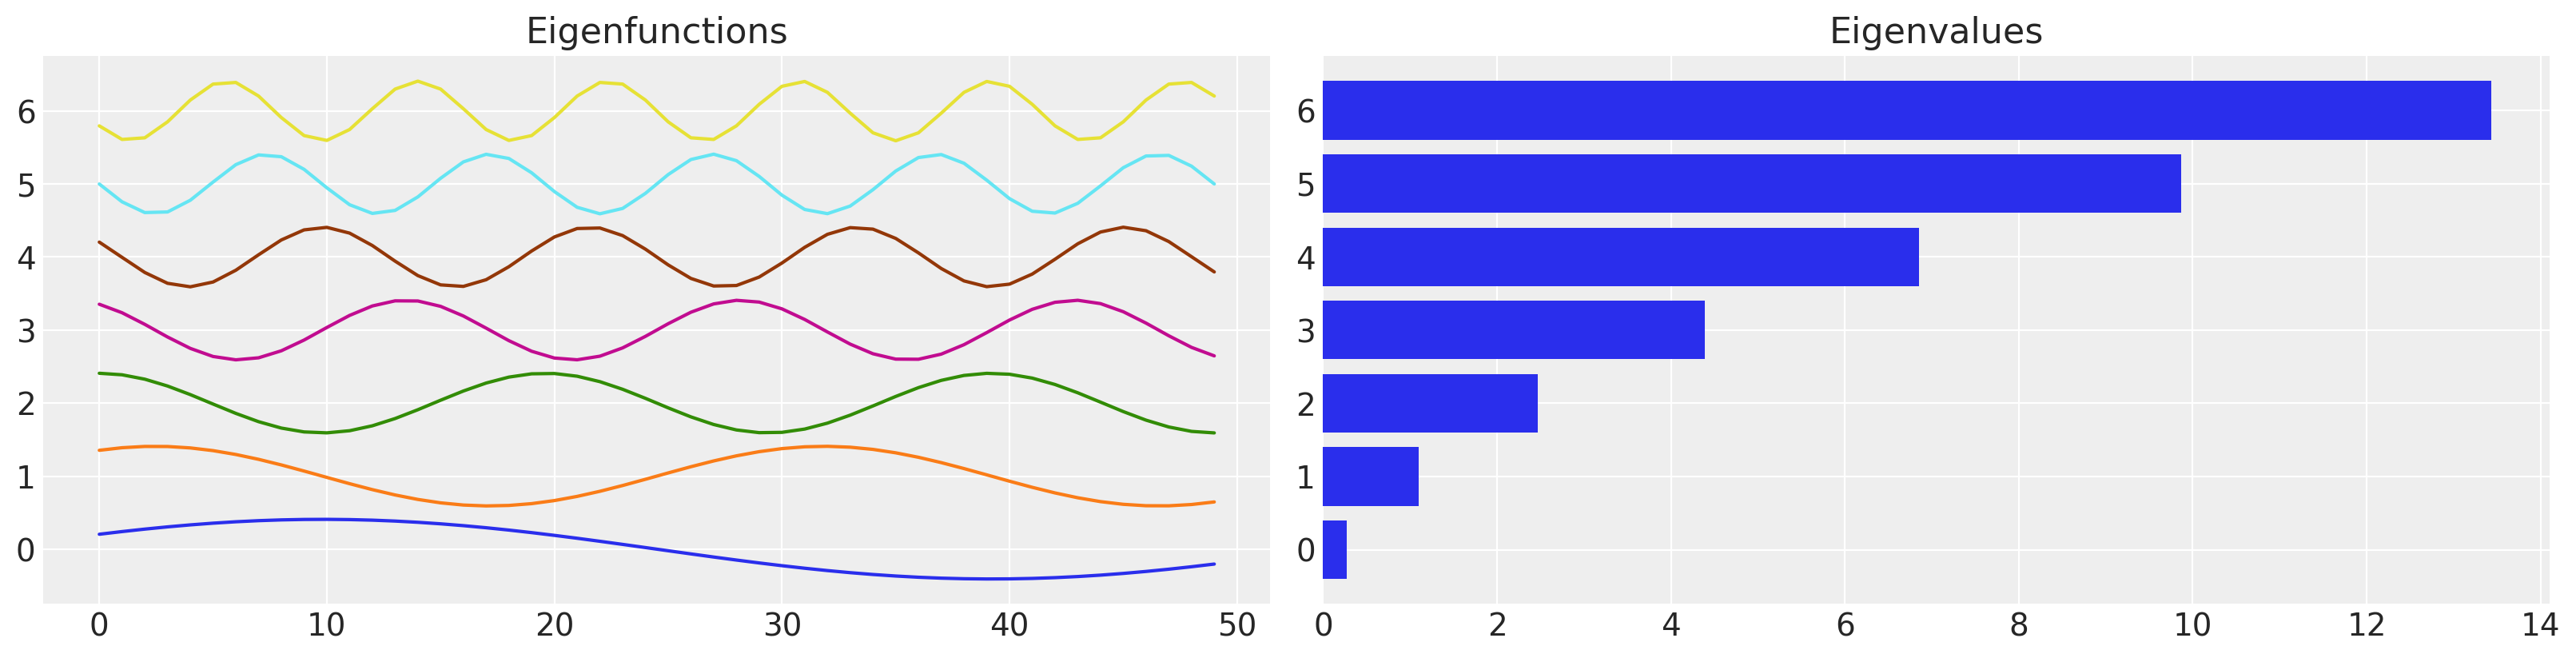

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].plot(eig_vecs + np.arange(m[0]));
axes[0].set_title("Eigenfunctions");
axes[1].barh(np.arange(m[0]), eig_vals[:, 0]);
axes[1].set_title("Eigenvalues");

In [41]:
import scipy.interpolate

In [73]:
interp = scipy.interpolate.interp1d(
    np.arange(len(passengers)), 
    np.log(passengers["#Passengers"]), 
    assume_sorted=True, 
    fill_value="extrapolate"
)
interpolate_log_passengers = interp(np.linspace(0, len(passengers), len(passengers) * 30))

In [92]:
with pm.Model(
    coords=dict(
        time=pd.date_range(
            passengers["Month"].min(), 
            passengers["Month"].max(), 
            len(interpolate_log_passengers)
        ))
) as model4:
    # центрируем данные, чтобы E[X] = 0: это распространённый приём, упрощающий рассуждения
    months = pm.MutableData(
        "months",
        # делим на 30, так как копируем код, который работал в помесячной шкале
        1/30 * (np.arange(len(interpolate_log_passengers)) - len(interpolate_log_passengers)//2), 
        dims="time")
    # скопируйте из предыдущей модели
    m_log_mean = ...
    log_trend = ...
    log_mean = ... # вычислите из months, log_trend, m_log_mean
    eps = ...

    # пора реализовать периодическую часть на признаках Фурье
    # сначала априорные распределения
    # используйте фрагмент кода выше
    alpha = ...
    seasonality = ...

    # время HSGP
    ls = ...
    alpha_r = ...
    cov = ...
    assert isinstance(cov, pm.gp.cov.ExpQuad)
    # формула из статьи для оптимального числа компонент аппроксимации
    # в этом примере получится 5-30 в зависимости от масштаба длины (lengthscale),
    # если получилось 100+, ваш масштаб длины вызывает вопросы
    m = np.ceil(1.75 * 1.25 / 24 * (max_months//2))
    # прочитайте https://www.pymc.io/projects/docs/en/stable/api/gp/generated/pymc.gp.HSGP.html
    # для инициализации HSGP используйте drop_first=True, не забудьте (cov * alpha_r)
    gp = ...
    assert isinstance(gp, pm.gp.HSGP)
    residual = gp.prior("structural", months[:, None], dims="time")

    mean = log_mean + seasonality + residual
    log_obs = pm.Normal("log_obs", mean , eps, observed=interpolate_log_passengers, dims="time")

Сэмплирование может занять время; если оно идёт слишком долго, попробуйте также chains=1.

In [95]:
with model4:
    trace4 = pm.sample(chains=1)
    trace4.extend(pm.sample_posterior_predictive(trace4))

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [m_log_mean, trend, alpha_s, ls, alpha_r, structural_hsgp_coeffs_, eps]


Sampling 1 chain for 1_000 tune and 1_000 draw iterations (1_000 + 1_000 draws total) took 334 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks
Sampling: [log_obs]


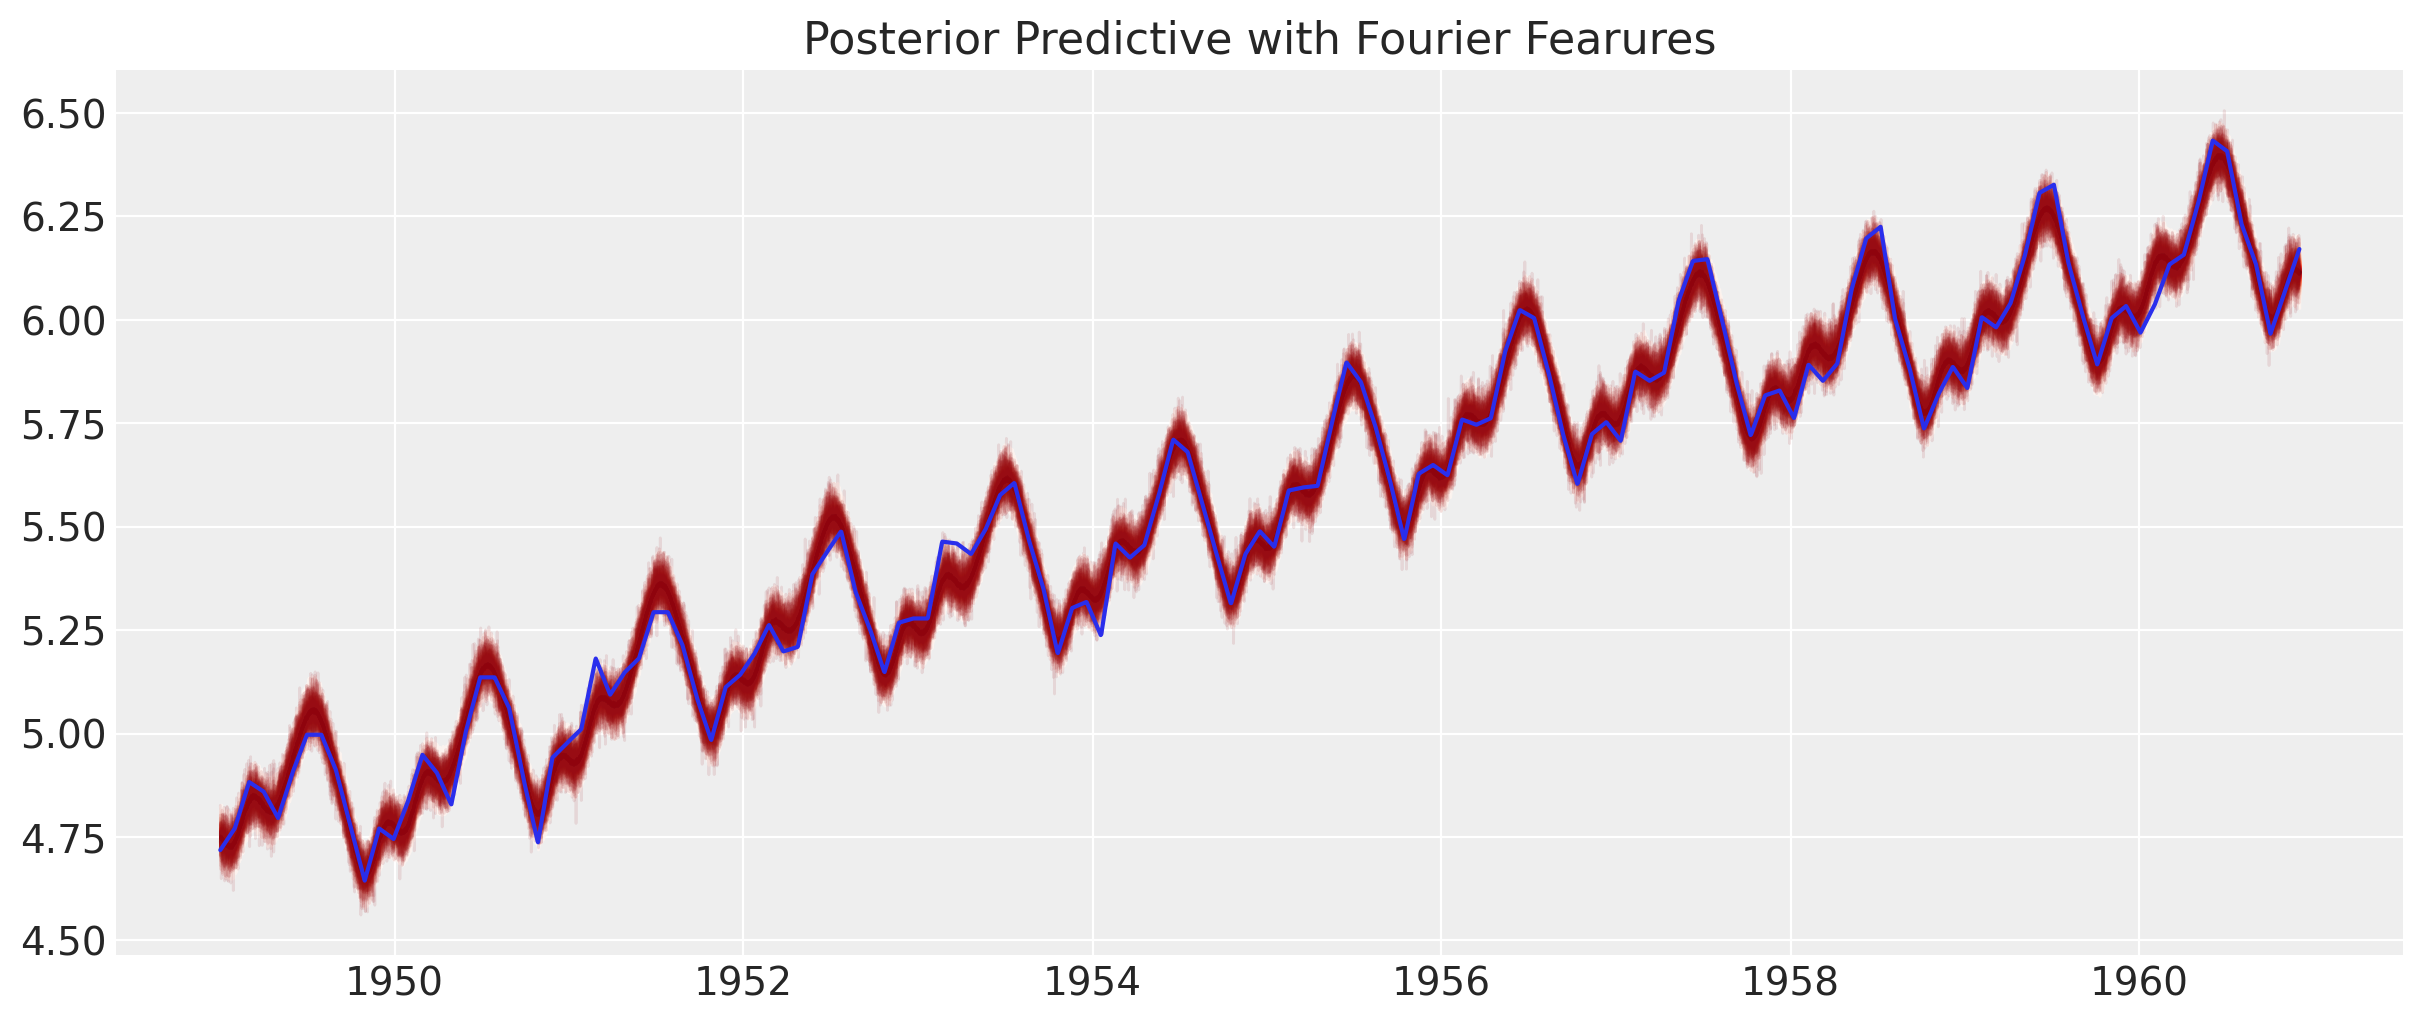

In [96]:
fig = plt.figure(figsize=(12, 5))
ax = fig.gca()


plot_gp_dist(ax, az.extract(trace4.posterior_predictive)["log_obs"].T, trace4.posterior_predictive.time.values)
ax.plot(trace4.posterior_predictive.time.values, interpolate_log_passengers)
plt.title("Posterior Predictive with Fourier Fearures");

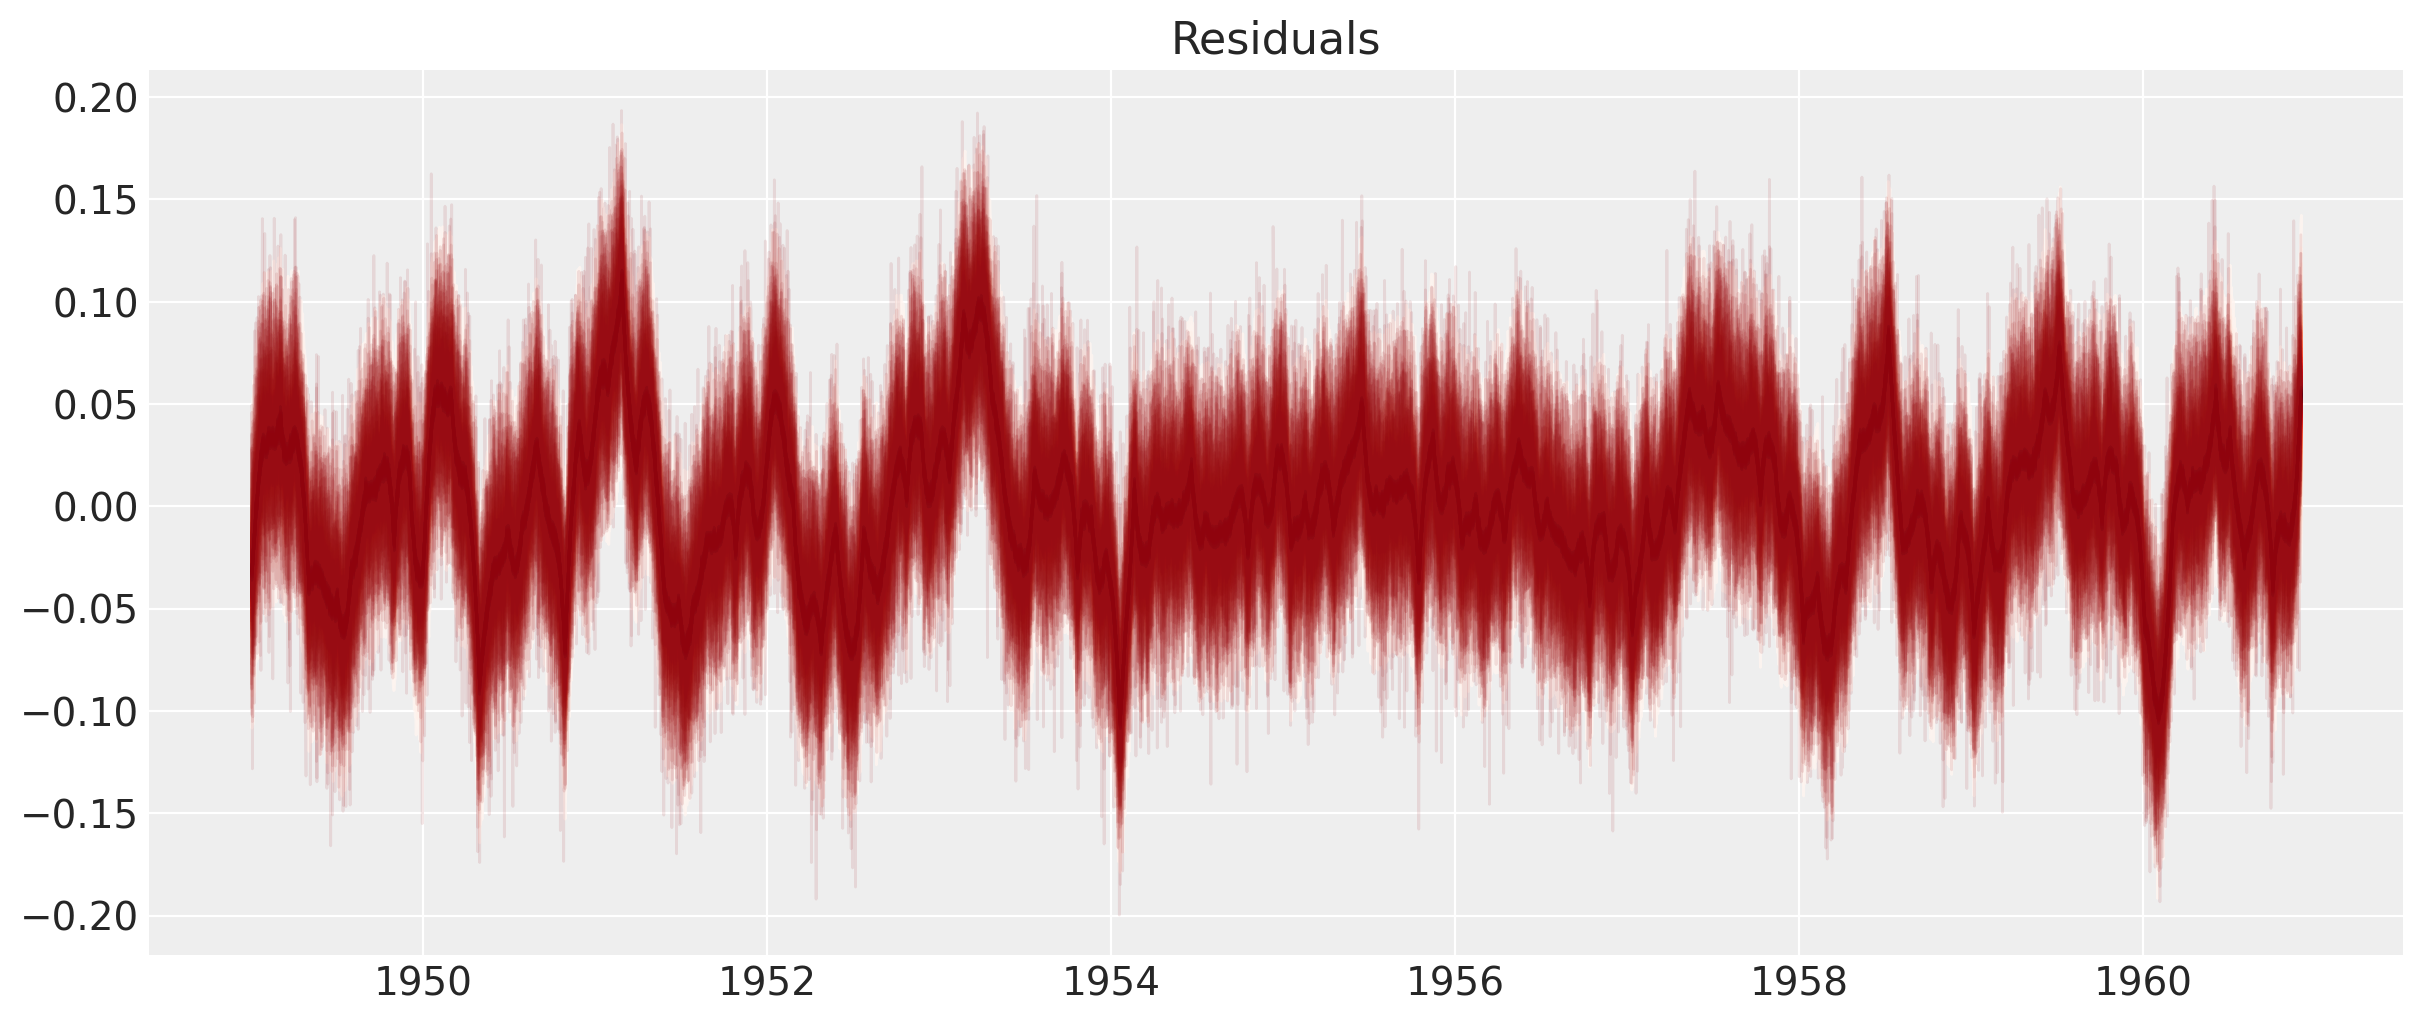

In [97]:
fig = plt.figure(figsize=(12, 5))
ax = fig.gca()

residuals = interpolate_log_passengers - az.extract(trace4.posterior_predictive)["log_obs"].values.T
plot_gp_dist(ax, residuals, trace4.posterior_predictive.time.values)
plt.title("Residuals");